# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [4]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [6]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [16]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [17]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters
    if (epoch + 1) % 10 == 0:
        print(f"{epoch + 1} loss : {loss} ")

print("Training finished!")

10 loss : 2.058530330657959 
20 loss : 1.6169278621673584 
30 loss : 2.3573431968688965 
40 loss : 1.6131678819656372 
50 loss : 1.6713107824325562 
Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

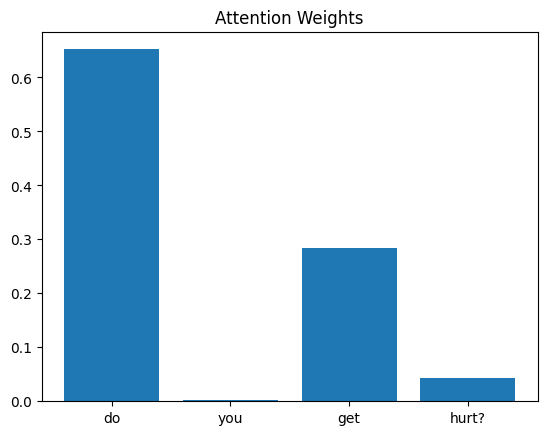

In [40]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.


In [23]:
df.shape

(168, 3)

In [32]:
random_list = [random.randint(1, df.shape[0]) for _ in range(3)]
random_list

[132, 138, 12]

In [56]:
def plot_attention(idx, with_max=False):
    question = df["question"][idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])   # slicing keeps the batch dimension

    n = min(len(words), weights.shape[1])           # in case the question was truncated to max length
    plt.bar(words[:n], weights[0, :n].tolist())
    plt.title(f"Attention Weights (question {idx})")
    plt.xticks(rotation=45)
    plt.show()

    if with_max:
      print(f"max word is '{words[np.argmax(weights)]}'")


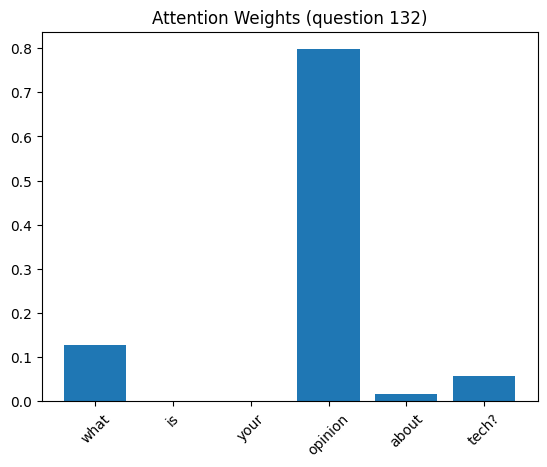

max word is 'opinion'


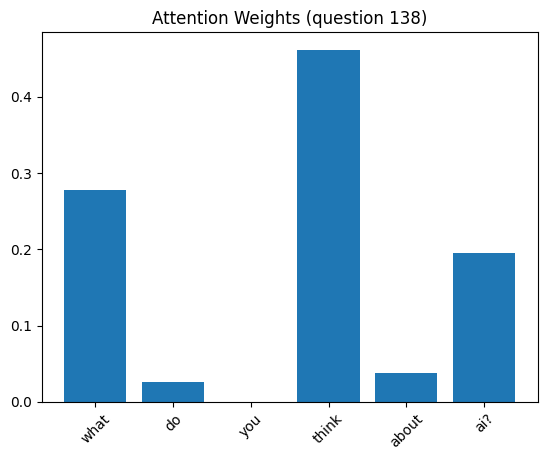

max word is 'think'


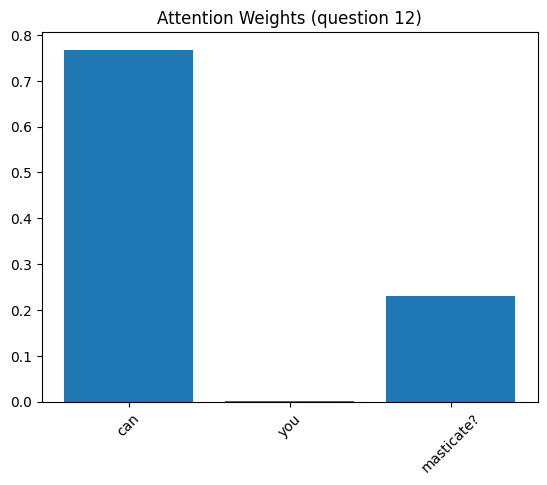

max word is 'can'


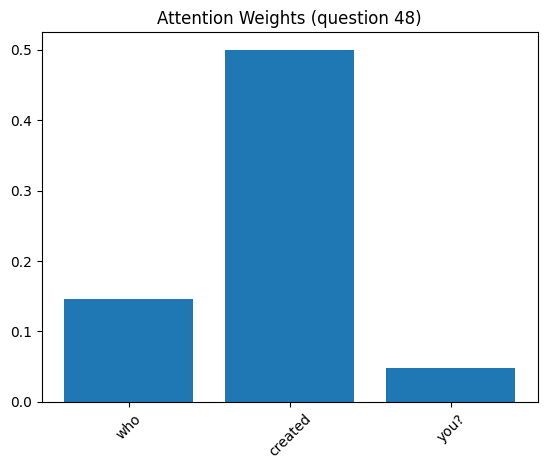

max word is 'created'


In [61]:
for i in [132, 138, 12, 48]:
  plot_attention(i, with_max=True)

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Yes, somewhat true, words like do and a get minimal weights and they carry no meaning, whereby words like clever, genius, and main actions in a sentence do get higher weights.

But still, some words carry small meaning and get high weight like you, that's, very, can.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

that was a pretty intelligent answer
that was a pretty genius answer


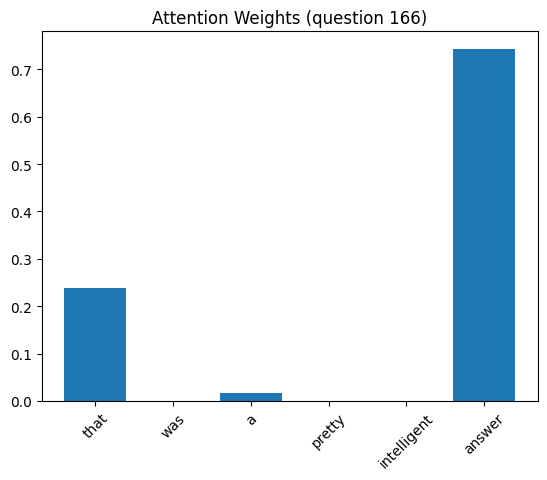

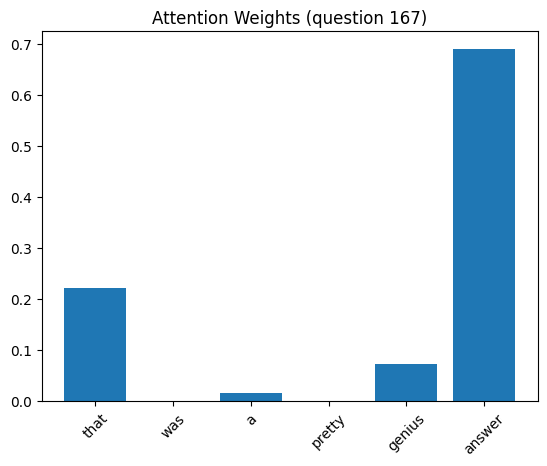

In [62]:
question1 = df['question'][166]
question2 = df['question'][167]

print(question1)
print(question2)

plot_attention(166)
plot_attention(167)

it does work as expected, though the main word genius didn't get similar weight as intelligent. But overall they got very similar distribution.

proving with KL divergence

In [66]:
def kl_attention(idx1, idx2, eps=1e-10):
    with torch.no_grad():
        _, w1 = model(X[idx1:idx1+1])
        _, w2 = model(X[idx2:idx2+1])

    # compare only up to the shorter question's real tokens
    n = min(len(df["question"][idx1].split()),
            len(df["question"][idx2].split()),
            w1.shape[1])

    p = w1[0, :n]
    q = w2[0, :n]
    p = p / p.sum()   # re-normalize after cutting off padding
    q = q / q.sum()

    return torch.sum(p * torch.log((p + eps) / (q + eps))).item()


0.07276155054569244


In [67]:
import itertools

with torch.no_grad():
    _, all_w = model(X)          # weights for every question at once

lengths = [len(q.split()) for q in df["question"]]
eps = 1e-10

def kl_from_weights(i, j):
    n = min(lengths[i], lengths[j], all_w.shape[1])
    p = all_w[i, :n] / all_w[i, :n].sum()
    q = all_w[j, :n] / all_w[j, :n].sum()
    return torch.sum(p * torch.log((p + eps) / (q + eps))).item()

kls = [kl_from_weights(i, j)
       for i, j in itertools.permutations(range(len(df)), 2)]

print("Average KL:", sum(kls) / len(kls))


Average KL: 1.8413803197517817


In [68]:
print(f"KL for these two samples {kl_attention(166, 167)}")

KL for these two samples 0.07276155054569244


Lower KL means the two weights distributions are very similar.  

What does it say about attention: attention learns which tokens matter for the task. It is driven by the meaning of the words and their role in the question, not by fixed positions.


